# Graphene Materials Transformer V4 — Colab + Streamlit + Cloudflare Tunnel

**End-to-end pipeline:** Materials Project API → Expanded Data → Inspection → Preprocessing → Structure Features → Extended Element Features → Transformer V4 → Graphene-like Ranking → Embedding PCA → Graphene-specific Screening → DFT Candidates → Streamlit Web Dashboard → Cloudflare Tunnel Public URL

**PCA is used only for interpretation and visualization. It is not used as a model input.**

## Before running
1. Set your Materials Project API key in Section 2.
2. In Colab: `Runtime` → `Change runtime type` → GPU recommended.
3. Run all cells.
4. At the end, click the generated Cloudflare URL to open the public web dashboard.

**Note:** Structure analysis can be slow. For the first run, keep `MAX_SAMPLES = 300` or `500`.


In [1]:
# 0. Install dependencies
!pip install mp-api pymatgen pandas torch matplotlib scikit-learn streamlit plotly -q

In [2]:
# 1. Imports and reproducibility
import os, random, copy, json, shutil, warnings, time, subprocess, threading, re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
OUTPUT_DIR='output'; APP_DIR='streamlit_app'
os.makedirs(OUTPUT_DIR,exist_ok=True); os.makedirs(APP_DIR,exist_ok=True)
MAX_SAMPLES=500

Using device: cpu


In [3]:
# 2. Materials Project API key
MP_API_KEY='H81zb7StpUYqB0XKEH3J31a9tCkj4e8z'
if not MP_API_KEY or MP_API_KEY=='YOUR_API_KEY_HERE':
    raise ValueError('Set your 32-character Materials Project API key.')
print('API key configured.')

API key configured.


In [4]:
# 3. Expanded Materials Project download with structure
try:
    from mp_api.client import MPRester
except ImportError:
    print("mp-api not found. Installing now...")
    !pip install mp-api pymatgen -q
    from mp_api.client import MPRester

def load_materials_project_data_v4(api_key,max_samples=MAX_SAMPLES,min_elements=1,max_elements=6,max_eah=.1,include_structure=True):
    print('[1] Downloading expanded Materials Project dataset...')
    fields=['material_id','formula_pretty','composition','band_gap','formation_energy_per_atom','energy_above_hull','is_stable','symmetry']
    if include_structure: fields.append('structure')
    records=[]
    with MPRester(api_key) as mpr:
        docs=mpr.materials.summary.search(num_elements=(min_elements,max_elements),energy_above_hull=(0.,max_eah),is_stable=True,fields=fields)
        for i,doc in enumerate(docs):
            if i>=max_samples: break
            atoms=[]
            for el,amt in doc.composition.items():
                z=int(el.Z); count=max(1,int(round(float(amt)))); atoms.extend([z]*count)
            if len(atoms)<1: continue
            atoms=atoms[:16]
            rec={'material_id':str(doc.material_id),'formula':doc.formula_pretty,'atomic_numbers':atoms,
                 'band_gap':float(doc.band_gap) if doc.band_gap is not None else np.nan,
                 'formation_energy':float(doc.formation_energy_per_atom) if doc.formation_energy_per_atom is not None else np.nan,
                 'energy_above_hull':float(doc.energy_above_hull) if doc.energy_above_hull is not None else np.nan,
                 'is_stable':bool(doc.is_stable),'has_structure':bool(include_structure and doc.structure is not None)}
            if include_structure and doc.structure is not None:
                try:
                    rec['n_sites_raw']=len(doc.structure); rec['structure_dict']=doc.structure.as_dict()
                except Exception:
                    rec['n_sites_raw']=np.nan; rec['structure_dict']=None
            else:
                rec['n_sites_raw']=np.nan; rec['structure_dict']=None
            records.append(rec)
    df=pd.DataFrame(records)
    print(f'Downloaded: {len(df):,} | With structure: {df["has_structure"].sum():,}')
    return df

df_raw=load_materials_project_data_v4(MP_API_KEY)
df_raw.to_csv(os.path.join(OUTPUT_DIR,'materials_project_raw_v4.csv'),index=False)

[1] Downloading expanded Materials Project dataset...


Output()

✓ Retrieved 32,534 SummaryDoc documents in 141.8s

Downloaded: 500 | With structure: 500


In [5]:
# 4. Inspect raw dataframe
def inspect_dataframe(df,name='df'):
    print('='*80); print(f'[{name}] Data inspection'); print('='*80)
    print(f'\nShape: {df.shape}'); print('\nInfo:'); df.info()
    numeric=df.select_dtypes(include=[np.number]).columns.tolist()
    if numeric: print('\nNumeric summary:'); print(df[numeric].describe().T)
    missing=df.isna().sum(); print('\nMissing values:'); print(missing[missing>0] if missing.sum() else 'No missing values.')
    if 'material_id' in df: print(f"\nDuplicate material_id rows: {df['material_id'].duplicated().sum()}")
    if 'formula' in df: print(f"Duplicate formula rows: {df['formula'].duplicated().sum()}")
    if 'atomic_numbers' in df:
        lengths=df['atomic_numbers'].apply(len); print('\nAtomic sequence length distribution:'); print(lengths.describe())
    print('\nTarget distributions:')
    for col in ['band_gap','formation_energy','energy_above_hull']:
        if col in df: print(f'{col}: min={df[col].min():.4f}, max={df[col].max():.4f}, mean={df[col].mean():.4f}, std={df[col].std():.4f}, unique={df[col].nunique()}')

inspect_dataframe(df_raw,'Raw expanded dataframe')

[Raw expanded dataframe] Data inspection

Shape: (500, 10)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   material_id        500 non-null    object 
 1   formula            500 non-null    object 
 2   atomic_numbers     500 non-null    object 
 3   band_gap           500 non-null    float64
 4   formation_energy   500 non-null    float64
 5   energy_above_hull  500 non-null    float64
 6   is_stable          500 non-null    bool   
 7   has_structure      500 non-null    bool   
 8   n_sites_raw        500 non-null    int64  
 9   structure_dict     500 non-null    object 
dtypes: bool(2), float64(3), int64(1), object(4)
memory usage: 32.4+ KB

Numeric summary:
                   count       mean        std      min       25%        50%  \
band_gap           500.0   1.264281   1.697154  0.00000  0.000000   0.350400   
for

In [6]:
# 5. Basic preprocessing
REQUIRED_COLUMNS=['material_id','formula','atomic_numbers','band_gap','formation_energy','energy_above_hull']
TARGET_COLS=['formation_energy','band_gap','energy_above_hull']
NONMETAL_Z={1,2,5,6,7,8,9,10,15,16,34,52}

def clean_atomic_numbers(x):
    if isinstance(x,(list,tuple,np.ndarray)): return [int(z) for z in x if 1<=int(z)<=118]
    return []

def composition_features(atoms):
    c=Counter(atoms); n=len(atoms)
    return pd.Series({'n_atoms':n,'z_mean':np.mean(atoms),'z_std':np.std(atoms) if n>1 else 0.,
        'carbon_ratio':c.get(6,0)/n,'group14_ratio':sum(z in {6,14,32,50} for z in atoms)/n,
        'metal_ratio':sum(z not in NONMETAL_Z for z in atoms)/n,'n_unique_elements':len(c)})

def preprocess_materials_df(df,max_atoms=16,remove_outliers=True,iqr_factor=3.):
    df=df.copy(); initial=len(df)
    missing=[c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing: raise ValueError(f'Missing columns: {missing}')
    df=df.drop_duplicates(subset=['material_id'],keep='first')
    df=df.dropna(subset=TARGET_COLS)
    df['atomic_numbers']=df['atomic_numbers'].apply(clean_atomic_numbers)
    df=df[df['atomic_numbers'].apply(len)>=1]
    if remove_outliers:
        before=len(df)
        for col in TARGET_COLS:
            q1,q3=df[col].quantile(.25),df[col].quantile(.75); iqr=q3-q1
            df=df[(df[col]>=q1-iqr_factor*iqr)&(df[col]<=q3+iqr_factor*iqr)]
        print(f'Outliers removed: {before-len(df)}')
    df['atomic_numbers']=df['atomic_numbers'].apply(lambda x:x[:max_atoms])
    df=df[df['atomic_numbers'].apply(len)>=1]
    df=pd.concat([df,df['atomic_numbers'].apply(composition_features)],axis=1)
    print(f'Initial: {initial}, Final: {len(df)}, Shape: {df.shape}')
    return df

df=preprocess_materials_df(df_raw)
inspect_dataframe(df,'Preprocessed dataframe')

Outliers removed: 0
Initial: 500, Final: 500, Shape: (500, 17)
[Preprocessed dataframe] Data inspection

Shape: (500, 17)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   material_id        500 non-null    object 
 1   formula            500 non-null    object 
 2   atomic_numbers     500 non-null    object 
 3   band_gap           500 non-null    float64
 4   formation_energy   500 non-null    float64
 5   energy_above_hull  500 non-null    float64
 6   is_stable          500 non-null    bool   
 7   has_structure      500 non-null    bool   
 8   n_sites_raw        500 non-null    int64  
 9   structure_dict     500 non-null    object 
 10  n_atoms            500 non-null    float64
 11  z_mean             500 non-null    float64
 12  z_std              500 non-null    float64
 13  carbon_ratio       500 non-null    float6

In [7]:
# 6. Structure feature extraction
from pymatgen.core import Structure
from pymatgen.analysis.local_env import CrystalNN

def extract_structure_features(structure_dict,max_neighbors=12):
    default={'n_sites':0,'mean_coordination_number':0.,'std_coordination_number':0.,'mean_bond_length':0.,
             'std_bond_length':0.,'mean_bond_angle':0.,'std_bond_angle':0.,'estimated_dimensionality':0,
             'carbon_fraction':0.,'three_coordinate_fraction':0.,'cc_bond_length_deviation':1.}
    if structure_dict is None: return default
    try: structure=Structure.from_dict(structure_dict)
    except Exception: return default
    n_sites=len(structure)
    carbon_indices=[i for i,s in enumerate(structure) if s.specie.Z==6]
    carbon_fraction=len(carbon_indices)/n_sites if n_sites else 0.
    try:
        cnn=CrystalNN(); coords=[]; bonds=[]; angles=[]; three_coord=0; cc_bonds=[]
        for i,site in enumerate(structure):
            try: neighbors=cnn.get_nn_info(structure,i)[:max_neighbors]
            except Exception: continue
            coords.append(len(neighbors))
            if len(neighbors)==3: three_coord+=1
            for nb in neighbors:
                try:
                    j=nb['site_index']; d=structure.get_distance(i,j); bonds.append(d)
                    if site.specie.Z==6 and structure[j].specie.Z==6: cc_bonds.append(d)
                except Exception: continue
            if len(neighbors)>=3:
                idx=[nb['site_index'] for nb in neighbors[:3]]
                try: angles.append(structure.get_angle(idx[0],i,idx[1]))
                except Exception: continue
        try:
            from pymatgen.analysis.dimensionality import get_dimensionality
            dimensionality=get_dimensionality(structure)
        except Exception: dimensionality=0
        cc_dev=float(np.mean(np.abs(np.array(cc_bonds)-1.42))) if cc_bonds else 1.
        return {'n_sites':n_sites,'mean_coordination_number':float(np.mean(coords)) if coords else 0.,
            'std_coordination_number':float(np.std(coords)) if len(coords)>1 else 0.,
            'mean_bond_length':float(np.mean(bonds)) if bonds else 0.,
            'std_bond_length':float(np.std(bonds)) if len(bonds)>1 else 0.,
            'mean_bond_angle':float(np.mean(angles)) if angles else 0.,
            'std_bond_angle':float(np.std(angles)) if len(angles)>1 else 0.,
            'estimated_dimensionality':int(dimensionality),'carbon_fraction':float(carbon_fraction),
            'three_coordinate_fraction':float(three_coord/n_sites) if n_sites else 0.,
            'cc_bond_length_deviation':cc_dev}
    except Exception: return default

print('[2] Extracting structure features. This may take several minutes.')
structure_rows=[]
for _,row in df_raw.iterrows():
    feats=extract_structure_features(row.get('structure_dict',None)); feats['material_id']=row['material_id']
    structure_rows.append(feats)
structure_features_df=pd.DataFrame(structure_rows)
df=df.merge(structure_features_df,on='material_id',how='left')
STRUCTURE_FEATURE_COLS=['n_sites','mean_coordination_number','std_coordination_number','mean_bond_length','std_bond_length','mean_bond_angle','std_bond_angle','estimated_dimensionality','carbon_fraction','three_coordinate_fraction','cc_bond_length_deviation']
for col in STRUCTURE_FEATURE_COLS:
    if col in df.columns: df[col]=df[col].fillna(0.)
df.to_csv(os.path.join(OUTPUT_DIR,'materials_with_structure_features.csv'),index=False)
print('\n[Structure feature summary]'); print(df[STRUCTURE_FEATURE_COLS].describe().T)

[2] Extracting structure features. This may take several minutes.

[Structure feature summary]
                           count       mean        std       min        25%  \
n_sites                    500.0  24.632000  29.319479  1.000000   6.000000   
mean_coordination_number   500.0   5.166187   2.759960  1.555556   3.000000   
std_coordination_number    500.0   1.141553   0.988177  0.000000   0.199852   
mean_bond_length           500.0   2.421182   0.494173  0.000000   2.096119   
std_bond_length            500.0   0.184767   0.204141  0.000000   0.033668   
mean_bond_angle            500.0  59.328497  32.978089  0.000000  45.000000   
std_bond_angle             500.0  32.947250  21.392822  0.000000  22.087226   
estimated_dimensionality   500.0   0.000000   0.000000  0.000000   0.000000   
carbon_fraction            500.0   0.005361   0.038952  0.000000   0.000000   
three_coordinate_fraction  500.0   0.127592   0.203286  0.000000   0.000000   
cc_bond_length_deviation   500.0   1

In [8]:
# 7. Train/validation split and target scaling
def make_train_val_split(df,test_size=.2,random_state=SEED):
    train_df,val_df=train_test_split(df,test_size=test_size,random_state=random_state,shuffle=True)
    target_scaler=StandardScaler(); target_scaler.fit(train_df[TARGET_COLS].values.astype(np.float32))
    train_df,val_df=train_df.copy(),val_df.copy()
    scaled=[c+'_scaled' for c in TARGET_COLS]
    train_df[scaled]=target_scaler.transform(train_df[TARGET_COLS].values.astype(np.float32))
    val_df[scaled]=target_scaler.transform(val_df[TARGET_COLS].values.astype(np.float32))
    print(f'Train: {len(train_df)}, Validation: {len(val_df)}')
    return train_df,val_df,target_scaler

train_df,val_df,target_scaler=make_train_val_split(df)
train_df.to_csv(os.path.join(OUTPUT_DIR,'train_df.csv'),index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR,'val_df.csv'),index=False)

Train: 400, Validation: 100


In [9]:
# 8. Extended element features: 9 dimensions
from pymatgen.core import Element

def get_extended_element_feature_vector(z):
    e=Element.from_Z(int(z))
    def safe(v,d): return float(v) if v is not None else float(d)
    try: group=float(e.group)
    except Exception: group=0.
    try: period=float(e.row)
    except Exception: period=0.
    return np.nan_to_num(np.array([safe(e.X,1.5),safe(e.atomic_radius,150.),safe(e.ionization_energy,8.),
        safe(e.melting_point,500.),safe(e.density_of_solid,5.),safe(e.atomic_mass,50.),group,period,float(z)],dtype=np.float32),nan=0.,posinf=0.,neginf=0.)

EXTENDED_ELEMENT_FEATURES=['electronegativity','atomic_radius','first_ionization_energy','melting_point','density','atomic_mass','group','period','atomic_number']
extended_matrix=np.vstack([get_extended_element_feature_vector(z) for z in range(1,119)])
extended_element_scaler=StandardScaler(); extended_element_scaler.fit(extended_matrix)

def get_element_feature_normalized(z):
    raw=get_extended_element_feature_vector(int(z))
    return torch.tensor(extended_element_scaler.transform(raw.reshape(1,-1))[0],dtype=torch.float32)

N_ELEMENT_FEATURES=len(EXTENDED_ELEMENT_FEATURES)
print(f'Extended element feature dimension: {N_ELEMENT_FEATURES}')

Extended element feature dimension: 9


In [10]:
# 9. Dataset and DataLoader
class RealMaterialDataset(Dataset):
    def __init__(self,dataframe,max_len=16):
        self.samples=[]
        for _,row in dataframe.iterrows():
            atoms=list(row['atomic_numbers'])[:max_len]
            if len(atoms)<1: continue
            feats=torch.stack([get_element_feature_normalized(z) for z in atoms])
            target=torch.tensor([row['formation_energy_scaled'],row['band_gap_scaled'],row['energy_above_hull_scaled']],dtype=torch.float32)
            self.samples.append((torch.tensor(atoms,dtype=torch.long),feats,target,row['formula']))
        print(f'Dataset size: {len(self.samples)}')
    def __len__(self): return len(self.samples)
    def __getitem__(self,idx): return self.samples[idx]

def collate_fn(batch):
    atoms_list,feats_list,targets,formulas=zip(*batch)
    max_len=max(a.size(0) for a in atoms_list); B=len(batch)
    pa=torch.zeros(B,max_len,dtype=torch.long); pf=torch.zeros(B,max_len,N_ELEMENT_FEATURES)
    mask=torch.ones(B,max_len,dtype=torch.bool)
    for i,(a,f) in enumerate(zip(atoms_list,feats_list)):
        L=a.size(0); pa[i,:L]=a; pf[i,:L]=f; mask[i,:L]=False
    return pa,pf,torch.stack(targets),formulas,mask

train_dataset=RealMaterialDataset(train_df); val_dataset=RealMaterialDataset(val_df)
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True,collate_fn=collate_fn)
val_loader=DataLoader(val_dataset,batch_size=32,shuffle=False,collate_fn=collate_fn)

Dataset size: 400
Dataset size: 100


In [11]:
# 10. Transformer V4 model
class MaterialsPropertyTransformerV4(nn.Module):
    def __init__(self,embed_dim=64,depth=3,nhead=4,dropout=.15,max_z=118,n_element_features=N_ELEMENT_FEATURES):
        super().__init__()
        self.atomic_embedding=nn.Embedding(max_z+1,embed_dim//2,padding_idx=0)
        self.feature_projection=nn.Sequential(nn.Linear(n_element_features,embed_dim//2),nn.LayerNorm(embed_dim//2),nn.GELU(),nn.Dropout(dropout))
        layer=nn.TransformerEncoderLayer(d_model=embed_dim,nhead=nhead,dim_feedforward=embed_dim*4,dropout=dropout,activation='gelu',batch_first=True,norm_first=True)
        self.transformer=nn.TransformerEncoder(layer,num_layers=depth)
        self.attention_pooling=nn.Linear(embed_dim,1); self.final_norm=nn.LayerNorm(embed_dim)
        self.heads=nn.ModuleDict({name:nn.Sequential(nn.Linear(embed_dim,32),nn.GELU(),nn.Dropout(dropout),nn.Linear(32,1)) for name in ['formation_energy','band_gap','energy_above_hull']})
        for p in self.parameters():
            if p.dim()>1: nn.init.xavier_uniform_(p)
    def forward(self,atoms,feats,key_padding_mask=None):
        a=self.atomic_embedding(atoms.clamp(0,118)); f=self.feature_projection(feats)
        x=torch.cat([a,f],dim=-1)
        x=self.transformer(x,src_key_padding_mask=key_padding_mask)
        logits=self.attention_pooling(x).squeeze(-1)
        if key_padding_mask is not None: logits=logits.masked_fill(key_padding_mask,-1e9)
        weights=F.softmax(logits,dim=-1)
        pooled=torch.bmm(weights.unsqueeze(1),x).squeeze(1)
        return {name:head(self.final_norm(pooled)) for name,head in self.heads.items()},self.final_norm(pooled)

model=MaterialsPropertyTransformerV4().to(device)
print(model)

MaterialsPropertyTransformerV4(
  (atomic_embedding): Embedding(119, 32, padding_idx=0)
  (feature_projection): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.15, inplace=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.15, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.15, inplace=False)
        (dropout2): Dropout(p=0.15, inpl

In [12]:
# 11. Training
def train_model(model,train_loader,val_loader,epochs=60,patience=10,lr=3e-4,weight_decay=.03):
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=weight_decay)
    scheduler=CosineAnnealingLR(optimizer,T_max=epochs,eta_min=1e-6)
    loss_weights=torch.tensor([1.,1.2,.2]).to(device)
    best=float('inf'); best_state=None; patience_counter=0
    history={'train':[],'val':[],'lr':[]}
    for epoch in range(1,epochs+1):
        model.train(); train_loss=0.
        for atoms,feats,targets,_,mask in train_loader:
            atoms,feats,targets,mask=atoms.to(device),feats.to(device),targets.to(device),mask.to(device)
            preds,_=model(atoms,feats,key_padding_mask=mask)
            pv=torch.cat([preds['formation_energy'],preds['band_gap'],preds['energy_above_hull']],dim=1)
            loss=(F.mse_loss(pv,targets,reduction='none')*loss_weights).mean()
            optimizer.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.); optimizer.step()
            train_loss+=loss.item()
        train_loss/=max(len(train_loader),1)
        model.eval(); val_loss=0.
        with torch.no_grad():
            for atoms,feats,targets,_,mask in val_loader:
                atoms,feats,targets,mask=atoms.to(device),feats.to(device),targets.to(device),mask.to(device)
                preds,_=model(atoms,feats,key_padding_mask=mask)
                pv=torch.cat([preds['formation_energy'],preds['band_gap'],preds['energy_above_hull']],dim=1)
                val_loss+=((F.mse_loss(pv,targets,reduction='none')*loss_weights).mean()).item()
        val_loss/=max(len(val_loader),1)
        scheduler.step(); current_lr=scheduler.get_last_lr()[0]
        history['train'].append(train_loss); history['val'].append(val_loss); history['lr'].append(current_lr)
        marker=''
        if val_loss<best:
            best=val_loss; best_state=copy.deepcopy(model.state_dict()); patience_counter=0; marker='  * Best'
        else: patience_counter+=1
        print(f'Epoch {epoch:02d} | Train {train_loss:.4f} | Val {val_loss:.4f} | LR {current_lr:.2e}{marker}')
        if patience_counter>=patience:
            print(f'\nEarly stopping at epoch {epoch}.'); break
    if best_state: model.load_state_dict(best_state)
    print(f'\nBest validation loss: {best:.4f}')
    return model,history

model,history=train_model(model,train_loader,val_loader)

Epoch 01 | Train 0.8713 | Val 0.7684 | LR 3.00e-04  * Best
Epoch 02 | Train 0.6422 | Val 0.5784 | LR 2.99e-04  * Best
Epoch 03 | Train 0.5493 | Val 0.5268 | LR 2.98e-04  * Best
Epoch 04 | Train 0.5300 | Val 0.4675 | LR 2.97e-04  * Best
Epoch 05 | Train 0.4696 | Val 0.4424 | LR 2.95e-04  * Best
Epoch 06 | Train 0.4237 | Val 0.4345 | LR 2.93e-04  * Best
Epoch 07 | Train 0.4268 | Val 0.3768 | LR 2.90e-04  * Best
Epoch 08 | Train 0.3957 | Val 0.3711 | LR 2.87e-04  * Best
Epoch 09 | Train 0.4214 | Val 0.3380 | LR 2.84e-04  * Best
Epoch 10 | Train 0.3589 | Val 0.3536 | LR 2.80e-04
Epoch 11 | Train 0.3514 | Val 0.3544 | LR 2.76e-04
Epoch 12 | Train 0.3377 | Val 0.3572 | LR 2.71e-04
Epoch 13 | Train 0.3790 | Val 0.3409 | LR 2.67e-04
Epoch 14 | Train 0.3223 | Val 0.3291 | LR 2.62e-04  * Best
Epoch 15 | Train 0.3409 | Val 0.3823 | LR 2.56e-04
Epoch 16 | Train 0.3378 | Val 0.3449 | LR 2.51e-04
Epoch 17 | Train 0.3131 | Val 0.3429 | LR 2.45e-04
Epoch 18 | Train 0.2903 | Val 0.3470 | LR 2.38e-04
Ep

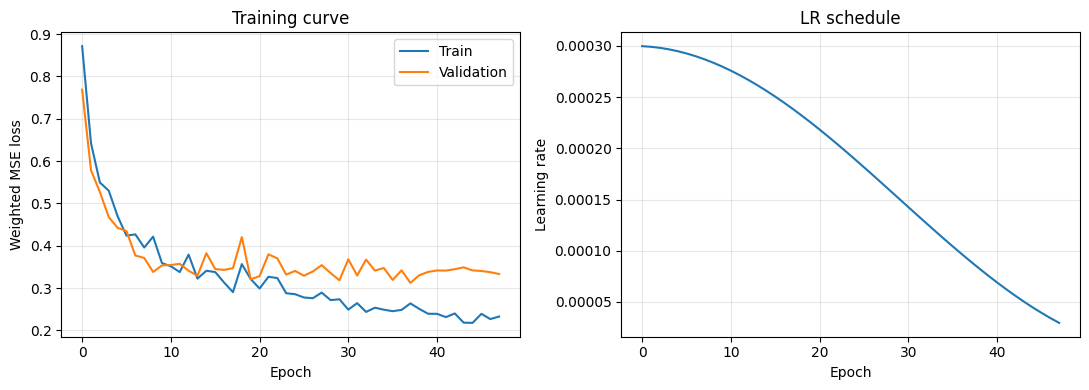

In [13]:
# 12. Training curve
plt.figure(figsize=(11,4))
plt.subplot(1,2,1); plt.plot(history['train'],label='Train'); plt.plot(history['val'],label='Validation'); plt.xlabel('Epoch'); plt.ylabel('Weighted MSE loss'); plt.title('Training curve'); plt.legend(); plt.grid(alpha=.3)
plt.subplot(1,2,2); plt.plot(history['lr']); plt.xlabel('Epoch'); plt.ylabel('Learning rate'); plt.title('LR schedule'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR,'training_curve.png'),dpi=200,bbox_inches='tight'); plt.show()

In [14]:
# 13. Graphene-like candidate ranking
def rank_graphene_like_candidates(model,dataframe,top_k=20,min_carbon_ratio=0.,max_eah=.1):
    model.eval()
    g_atoms=torch.tensor([[6,6,6,6]]).to(device)
    g_feats=torch.stack([get_element_feature_normalized(6) for _ in range(4)]).unsqueeze(0).to(device)
    g_mask=torch.zeros(1,4,dtype=torch.bool).to(device)
    with torch.no_grad(): _,g_emb=model(g_atoms,g_feats,key_padding_mask=g_mask)
    rows=[]
    with torch.no_grad():
        for _,row in dataframe.iterrows():
            atoms=list(row['atomic_numbers'])[:16]
            if len(atoms)<1: continue
            while len(atoms)<4: atoms.append(atoms[0])
            at=torch.tensor([atoms]).to(device)
            ft=torch.stack([get_element_feature_normalized(z) for z in atoms]).unsqueeze(0).to(device)
            mask=torch.zeros(1,len(atoms),dtype=torch.bool).to(device)
            preds,emb=model(at,ft,key_padding_mask=mask)
            sim=F.cosine_similarity(emb,g_emb,dim=-1).item()
            sp=np.array([[preds['formation_energy'].item(),preds['band_gap'].item(),preds['energy_above_hull'].item()]])
            rp=target_scaler.inverse_transform(sp)[0]
            rows.append({'material_id':row['material_id'],'formula':row['formula'],'similarity':sim,
                'carbon_ratio':row.get('carbon_ratio',0.),'formation_energy':row['formation_energy'],
                'energy_above_hull':row['energy_above_hull'],'band_gap':row['band_gap'],
                'predicted_formation_energy':rp[0],'predicted_band_gap':rp[1],'predicted_energy_above_hull':rp[2]})
    cand=pd.DataFrame(rows)
    cand=cand[(cand['carbon_ratio']>=min_carbon_ratio)&(cand['energy_above_hull']<=max_eah)].copy()
    cand['formation_rank']=cand['formation_energy'].rank(ascending=True)
    cand['stability_rank']=cand['energy_above_hull'].rank(ascending=True)
    cand['similarity_rank']=cand['similarity'].rank(ascending=False)
    cand['composite_score']=.5*cand['similarity_rank']+.3*cand['formation_rank']+.2*cand['stability_rank']
    cand=cand.sort_values('composite_score',ascending=True)
    print(f'\n[Graphene-like composite ranking — Top {top_k}]')
    print(cand.head(top_k)[['formula','similarity','carbon_ratio','formation_energy','energy_above_hull','band_gap','composite_score']].to_string(index=False))
    cand.to_csv(os.path.join(OUTPUT_DIR,'graphene_like_candidates_ranked.csv'),index=False)
    return cand

graphene_candidates=rank_graphene_like_candidates(model,df)


[Graphene-like composite ranking — Top 20]
     formula  similarity  carbon_ratio  formation_energy  energy_above_hull  band_gap  composite_score
    AlNi2BO5    0.862373         0.000         -2.320189                0.0  3.621100             77.9
     AgMoPO6    0.873714         0.000         -1.981106                0.0  2.096200             78.1
Ag9P14(OF)28    0.839584         0.000         -2.369994                0.0  0.026500             92.0
  Al2(MoO4)3    0.830746         0.000         -2.403986                0.0  3.537400             98.6
   AgMo6Cl13    0.857699         0.000         -1.282729                0.0  2.635800            105.4
    Ag2B8O13    0.813530         0.000         -2.510656                0.0  3.265100            105.6
    AgBH2OF4    0.813530         0.000         -2.162864                0.0  3.044000            113.1
Ag2Ge(S2O7)3    0.835038         0.000         -1.599948                0.0  2.807200            113.3
Ag2Sn(S2O7)3    0.821841     


[Transformer embedding PCA]
PC1: 42.28% explained variance
PC2: 17.54% explained variance
Cumulative: 59.82%


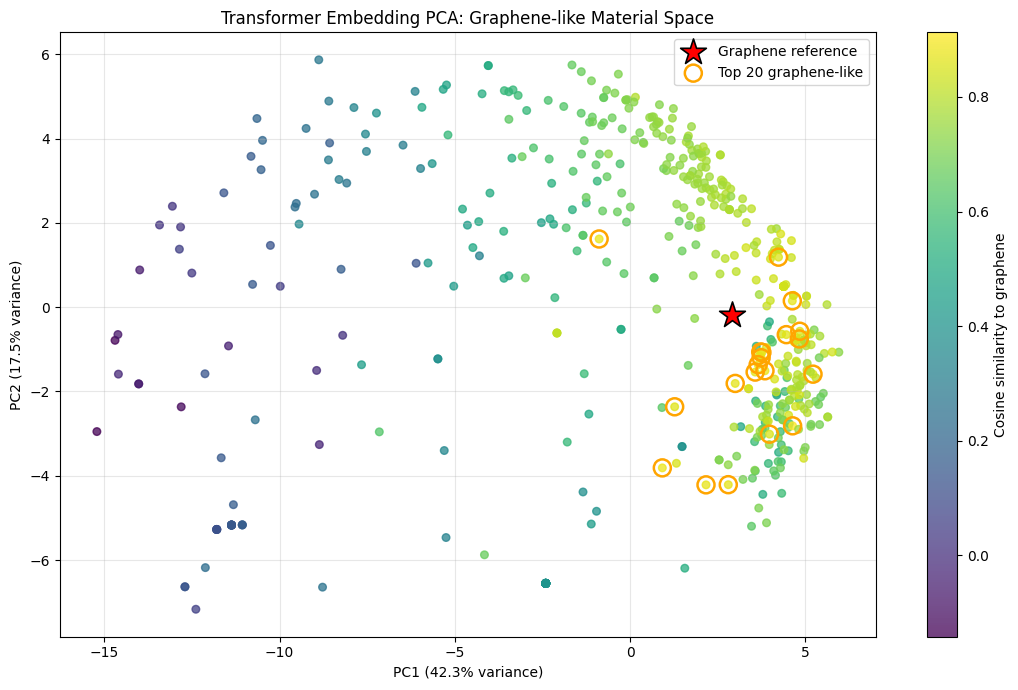


Top graphene-like materials in PCA space:
material_id      formula  similarity       PC1       PC2
    mp-9956       AlCr2C    0.912784  4.633760 -2.815937
    mp-1591        Al4C3    0.881306  0.918250 -3.813754
 mp-1029975    Al2(CN2)3    0.879267 -0.884670  1.617655
 mp-1214897  Al2(Ni7B2)3    0.878489  3.735733 -1.199973
 mp-1228540      Al2VNi9    0.878168  3.845038 -1.509547
  mp-637575      AlCr3B4    0.875335  2.164061 -4.216293
 mp-1228832      AlNi6Ge    0.874067  3.725066 -1.064031
   mp-14029      AgMoPO6    0.873714  4.625653  0.149614
  mp-505472 Al3(Ni10B3)2    0.872405  3.652110 -1.364892
  mp-861953      AlFeRh2    0.870983  4.823759 -0.754233


In [15]:
# 14. Transformer → Embedding → PCA → Interpretation
PCA_COMPONENTS=2; MAX_PCA_POINTS=1000

def build_material_embeddings(model,dataframe,max_atoms=16,max_points=MAX_PCA_POINTS):
    model.eval()
    g_atoms=torch.tensor([[6,6,6,6]]).to(device)
    g_feats=torch.stack([get_element_feature_normalized(6) for _ in range(4)]).unsqueeze(0).to(device)
    g_mask=torch.zeros(1,4,dtype=torch.bool).to(device)
    with torch.no_grad(): _,g_emb=model(g_atoms,g_feats,key_padding_mask=g_mask)
    g_emb_np=g_emb.cpu().numpy()
    sample=dataframe.copy()
    if len(sample)>max_points: sample=sample.sample(n=max_points,random_state=SEED).reset_index(drop=True)
    embeddings,ids,formulas,sims=[],[],[],[]
    with torch.no_grad():
        for _,row in sample.iterrows():
            atoms=list(row['atomic_numbers'])[:max_atoms]
            if len(atoms)<1: continue
            while len(atoms)<4: atoms.append(atoms[0])
            at=torch.tensor([atoms]).to(device)
            ft=torch.stack([get_element_feature_normalized(z) for z in atoms]).unsqueeze(0).to(device)
            mask=torch.zeros(1,len(atoms),dtype=torch.bool).to(device)
            _,emb=model(at,ft,key_padding_mask=mask)
            sim=F.cosine_similarity(emb,g_emb,dim=-1).item()
            embeddings.append(emb.cpu().numpy()[0]); ids.append(row['material_id']); formulas.append(row['formula']); sims.append(sim)
    return pd.DataFrame({'material_id':ids,'formula':formulas,'similarity':sims}),np.vstack(embeddings),g_emb_np

def apply_embedding_pca(emb_df,embeddings,graphene_embedding,n_components=PCA_COMPONENTS):
    scaler=StandardScaler(); scaled=scaler.fit_transform(embeddings)
    pca=PCA(n_components=n_components); pca_embeddings=pca.fit_transform(scaled)
    graphene_point=pca.transform(scaler.transform(graphene_embedding))[0]
    for i in range(n_components): emb_df[f'PC{i+1}']=pca_embeddings[:,i]
    print('\n[Transformer embedding PCA]')
    for i,r in enumerate(pca.explained_variance_ratio_,1): print(f'PC{i}: {r*100:.2f}% explained variance')
    print(f'Cumulative: {pca.explained_variance_ratio_.sum()*100:.2f}%')
    return emb_df,pca,scaler,graphene_point

def plot_graphene_embedding_pca(emb_df,graphene_point,pca_model,top_k=20):
    top=emb_df['similarity'].nlargest(top_k).index
    plt.figure(figsize=(11,7))
    sc=plt.scatter(emb_df['PC1'],emb_df['PC2'],c=emb_df['similarity'],cmap='viridis',s=30,alpha=.75)
    plt.scatter(graphene_point[0],graphene_point[1],color='red',marker='*',s=380,edgecolors='black',linewidths=1.2,label='Graphene reference',zorder=5)
    plt.scatter(emb_df.loc[top,'PC1'],emb_df.loc[top,'PC2'],facecolors='none',edgecolors='orange',s=150,linewidths=1.8,label=f'Top {top_k} graphene-like',zorder=4)
    plt.colorbar(sc,label='Cosine similarity to graphene')
    plt.xlabel(f"PC1 ({pca_model.explained_variance_ratio_[0]*100:.1f}% variance)")
    plt.ylabel(f"PC2 ({pca_model.explained_variance_ratio_[1]*100:.1f}% variance)")
    plt.title('Transformer Embedding PCA: Graphene-like Material Space'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
    path=os.path.join(OUTPUT_DIR,'graphene_embedding_pca.png'); plt.savefig(path,dpi=200,bbox_inches='tight'); plt.show(); return path

embedding_df,material_embeddings,graphene_embedding_numpy=build_material_embeddings(model,df)
embedding_df,PCA_MODEL,PCA_SCALER,graphene_pca_point=apply_embedding_pca(embedding_df,material_embeddings,graphene_embedding_numpy)
pca_plot_path=plot_graphene_embedding_pca(embedding_df,graphene_pca_point,PCA_MODEL)
embedding_df.to_csv(os.path.join(OUTPUT_DIR,'graphene_embedding_pca.csv'),index=False)
pca_metadata={'method':'Transformer embedding PCA','purpose':'interpretation_and_visualization_only','n_samples':int(len(embedding_df)),
 'embedding_dimension':int(material_embeddings.shape[1]),'n_components':int(PCA_MODEL.n_components_),
 'explained_variance_ratio':PCA_MODEL.explained_variance_ratio_.tolist(),
 'cumulative_explained_variance':float(PCA_MODEL.explained_variance_ratio_.sum()),
 'graphene_pca_coordinates':graphene_pca_point.tolist()}
with open(os.path.join(OUTPUT_DIR,'pca_metadata.json'),'w',encoding='utf-8') as f: json.dump(pca_metadata,f,ensure_ascii=False,indent=2)
print('\nTop graphene-like materials in PCA space:')
print(embedding_df.sort_values('similarity',ascending=False).head(10).to_string(index=False))

In [16]:
# 15. Graphene-specific structural screening
def graphene_specific_score(row):
    carbon_score=np.clip(row.get('carbon_fraction',0.),0,1)
    coordination_score=1.-min(abs(row.get('mean_coordination_number',0.)-3.)/3.,1.)
    bond_score=1.-min(row.get('cc_bond_length_deviation',1.)/1.,1.)
    two_d_score=1. if row.get('estimated_dimensionality',0)==2 else 0.
    three_coord_score=np.clip(row.get('three_coordinate_fraction',0.),0,1)
    return float(.30*carbon_score+.20*coordination_score+.20*bond_score+.20*two_d_score+.10*three_coord_score)

df['graphene_structure_score']=df.apply(graphene_specific_score,axis=1)
print('\n[Graphene-specific structural screening]')
print(df.sort_values('graphene_structure_score',ascending=False)[['formula','graphene_structure_score','carbon_fraction','mean_coordination_number','cc_bond_length_deviation','estimated_dimensionality']].head(20).to_string(index=False))
df.to_csv(os.path.join(OUTPUT_DIR,'materials_with_graphene_scores.csv'),index=False)


[Graphene-specific structural screening]
      formula  graphene_structure_score  carbon_fraction  mean_coordination_number  cc_bond_length_deviation  estimated_dimensionality
    Al2(CN2)3                  0.318182         0.272727                  3.272727                       1.0                         0
     AgHg2PO4                  0.275000         0.000000                  3.000000                       1.0                         0
    AgHg2AsO4                  0.275000         0.000000                  3.000000                       1.0                         0
       Al3BC3                  0.261905         0.428571                  4.000000                       1.0                         0
       Ag2CO3                  0.261111         0.166667                  2.666667                       1.0                         0
   Al4(B2O5)3                  0.248000         0.000000                  3.360000                       1.0                         0
      Al2PbO4

In [17]:
# 16. DFT validation candidates
def create_dft_validation_candidates(embedding_df,df,top_k=50):
    merged=embedding_df.merge(df,on='material_id',how='left')
    for col in ['similarity','graphene_structure_score','formation_energy','energy_above_hull']:
        if col not in merged: merged[col]=0.
    merged['similarity_rank']=merged['similarity'].rank(ascending=False)
    merged['structure_rank']=merged['graphene_structure_score'].rank(ascending=False)
    merged['formation_rank']=merged['formation_energy'].rank(ascending=True)
    merged['stability_rank']=merged['energy_above_hull'].rank(ascending=True)
    merged['dft_priority_score']=.35*merged['similarity_rank']+.30*merged['structure_rank']+.20*merged['formation_rank']+.15*merged['stability_rank']
    merged=merged.sort_values('dft_priority_score',ascending=True)
    cols=['material_id','formula','similarity','graphene_structure_score','carbon_fraction','mean_coordination_number','cc_bond_length_deviation','estimated_dimensionality','formation_energy','energy_above_hull','band_gap','dft_priority_score']
    cols=[c for c in cols if c in merged.columns]
    dft=merged.head(top_k)[cols].copy()
    path=os.path.join(OUTPUT_DIR,'dft_validation_candidates.csv')
    dft.to_csv(path,index=False)
    print(f'\n[DFT validation candidates — Top {top_k}]')
    print(dft.to_string(index=False))
    print(f'\nSaved: {path}')
    return dft

dft_candidates=create_dft_validation_candidates(embedding_df,df,top_k=50)


[DFT validation candidates — Top 50]
material_id  similarity  graphene_structure_score  carbon_fraction  mean_coordination_number  cc_bond_length_deviation  estimated_dimensionality  formation_energy  energy_above_hull  band_gap  dft_priority_score
   mp-14029    0.873714                  0.214815         0.000000                  3.111111                       1.0                         0         -1.981106                0.0  2.096200              72.275
  mp-554873    0.813530                  0.223188         0.000000                  2.826087                       1.0                         0         -2.510656                0.0  3.265100              87.625
 mp-1195618    0.839584                  0.205063         0.000000                  2.658228                       1.0                         0         -2.369994                0.0  0.026500              88.775
 mp-1214988    0.857699                  0.213333         0.000000                  3.400000                      

In [18]:
# 17. Save model and metadata
run_metadata={'seed':SEED,'device':str(device),'raw_rows':int(len(df_raw)),'preprocessed_rows':int(len(df)),
 'train_rows':int(len(train_df)),'validation_rows':int(len(val_df)),'target_columns':TARGET_COLS,
 'target_scaler_mean':target_scaler.mean_.tolist(),'target_scaler_scale':target_scaler.scale_.tolist(),
 'best_validation_loss':min(history['val']),'epochs_run':len(history['train']),
 'element_feature_dimension':N_ELEMENT_FEATURES,'pca_components':int(PCA_MODEL.n_components_),
 'pca_explained_variance_ratio':PCA_MODEL.explained_variance_ratio_.tolist()}
with open(os.path.join(OUTPUT_DIR,'run_metadata.json'),'w',encoding='utf-8') as f: json.dump(run_metadata,f,ensure_ascii=False,indent=2)
torch.save({'model_state_dict':model.state_dict(),'target_scaler_mean':target_scaler.mean_,'target_scaler_scale':target_scaler.scale_,'history':history},os.path.join(OUTPUT_DIR,'graphene_materials_transformer_v4.pt'))
print('\nSaved files:')
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f'- {fn}: {os.path.getsize(os.path.join(OUTPUT_DIR,fn))/1024/1024:.3f} MB')


Saved files:
- dft_validation_candidates.csv: 0.006 MB
- graphene_embedding_pca.csv: 0.027 MB
- graphene_embedding_pca.png: 0.335 MB
- graphene_like_candidates_ranked.csv: 0.077 MB
- graphene_materials_transformer_v4.pt: 0.636 MB
- materials_project_raw_v4.csv: 2.494 MB
- materials_with_graphene_scores.csv: 2.579 MB
- materials_with_structure_features.csv: 2.572 MB
- pca_metadata.json: 0.000 MB
- run_metadata.json: 0.001 MB
- train_df.csv: 2.062 MB
- training_curve.png: 0.126 MB
- val_df.csv: 0.523 MB


In [19]:
# 18. Create Streamlit web dashboard
app_code = """import os, json
import pandas as pd
import numpy as np
import streamlit as st
import plotly.express as px

st.set_page_config(page_title="Graphene Materials Transformer V4", page_icon="🧪", layout="wide")
OUTPUT_DIR = "../output"
APP_DIR = "streamlit_app"

SHARED_APP_URL = "https://ais-pre-fhmdywc77c7anvjmi6fi36-11187936285.asia-northeast1.run.app"

@st.cache_data
def load_csv(path):
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()

@st.cache_data
def load_json(path):
    return json.load(open(path, encoding="utf-8")) if os.path.exists(path) else {}

candidates = load_csv(os.path.join(OUTPUT_DIR, "graphene_like_candidates_ranked.csv"))
embedding = load_csv(os.path.join(OUTPUT_DIR, "graphene_embedding_pca.csv"))
dft = load_csv(os.path.join(OUTPUT_DIR, "dft_validation_candidates.csv"))
materials = load_csv(os.path.join(OUTPUT_DIR, "materials_with_graphene_scores.csv"))
metadata = load_json(os.path.join(OUTPUT_DIR, "run_metadata.json"))
pca_metadata = load_json(os.path.join(OUTPUT_DIR, "pca_metadata.json"))

st.title("🧪 Graphene Materials Transformer V4")
st.markdown("**Structure-aware graphene-like material discovery dashboard**")

try:
    public_url = open(os.path.join("public_url.txt")).read().strip()
except Exception:
    public_url = None

if public_url:
    st.sidebar.markdown(f'<div style="padding:14px;border-radius:12px;background:#0f2027;color:white;text-align:center"><b>🚀 Cloudflare Tunnel</b><br><br><a href="{public_url}" target="_blank" style="display:inline-block;padding:10px 18px;background:#00d1b2;color:#002;border-radius:10px;text-decoration:none;font-weight:bold">Open Tunnel</a><br><br><span style="font-size:12px">{public_url}</span></div>', unsafe_allow_html=True)

# --- WEB 화면 좌측 하단 앱 공유 URL 추가 섹션 (Bottom-Left Sidebar Shared App URL) ---
st.sidebar.markdown("---")
st.sidebar.markdown(f'''<div style="padding:14px;border-radius:12px;background:linear-gradient(135deg,#064e3b,#0f2027);border:1px solid #10b981;color:white;text-align:center;box-shadow:0 4px 12px rgba(16,185,129,0.25)">
<span style="display:inline-block;padding:3px 8px;border-radius:6px;background:rgba(16,185,129,0.25);color:#34d399;font-size:11px;font-weight:bold;margin-bottom:6px">🟢 LIVE SHARED URL</span><br>
<b style="font-size:13px;color:#f8fafc">🌐 배포 앱 공유 URL</b><br>
<div style="margin:8px 0;padding:8px;background:#090d16;border-radius:8px;border:1px solid #1e293b;word-break:break-all;font-family:monospace;font-size:10.5px;color:#7dd3fc">
{SHARED_APP_URL}
</div>
<a href="{SHARED_APP_URL}" target="_blank" style="display:inline-block;width:100%;padding:8px 0;background:#10b981;color:#022c22;border-radius:8px;text-decoration:none;font-weight:bold;font-size:12px;margin-bottom:6px">🚀 새 창에서 열기</a>
<span style="font-size:10px;color:#94a3b8">Google Cloud Run 실시간 배포 링크</span>
</div>''', unsafe_allow_html=True)

tab1, tab2, tab3, tab4, tab5 = st.tabs(["📌 Overview", "🧲 Graphene-like Candidates", "🗺️ Embedding PCA", "🧪 DFT Candidates", "📁 Material Explorer"])

with tab1:
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Materials", f"{len(materials):,}" if not materials.empty else "N/A")
    c2.metric("Graphene-like candidates", f"{len(candidates):,}" if not candidates.empty else "N/A")
    c3.metric("DFT candidates", f"{len(dft):,}" if not dft.empty else "N/A")
    c4.metric("Best val loss", f"{metadata.get('best_validation_loss', 0):.4f}" if metadata else "N/A")
    st.markdown("""```text\nMaterials Project API → Preprocessing → Structure Features → Transformer V4 → Graphene Similarity → PCA → DFT Candidates```""")
    if os.path.exists(os.path.join(OUTPUT_DIR, "training_curve.png")):
        st.image(os.path.join(OUTPUT_DIR, "training_curve.png"), use_container_width=True)

with tab2:
    st.subheader("🧲 Graphene-like Candidate Ranking")
    if candidates.empty: st.warning("No candidate file found.")
    else:
        cols = [c for c in ['formula', 'similarity', 'carbon_ratio', 'formation_energy', 'energy_above_hull', 'band_gap', 'composite_score'] if c in candidates]
        st.dataframe(candidates.head(20)[cols], use_container_width=True, hide_index=True)
        st.download_button("⬇️ Download candidates CSV", candidates.to_csv(index=False).encode('utf-8-sig'), "graphene_like_candidates_ranked.csv", "text/csv")
        if 'similarity' in candidates and 'composite_score' in candidates:
            fig = px.scatter(candidates.head(20), x='similarity', y='composite_score', hover_name='formula', title='Graphene Similarity vs Composite Ranking Score')
            st.plotly_chart(fig, use_container_width=True)

with tab3:
    st.subheader("🗺️ Transformer Embedding PCA")
    if embedding.empty: st.warning("No PCA file found.")
    else:
        min_sim = st.slider("Minimum cosine similarity", float(embedding['similarity'].min()), float(embedding['similarity'].max()), float(embedding['similarity'].min()))
        filtered = embedding[embedding['similarity'] >= min_sim]
        fig = px.scatter(filtered, x='PC1', y='PC2', color='similarity', hover_name='formula', color_continuous_scale='Viridis', title='Transformer Embedding PCA: Graphene-like Material Space')
        fig.update_traces(marker=dict(size=7, opacity=.8))
        st.plotly_chart(fig, use_container_width=True)
        st.download_button("⬇️ Download PCA CSV", embedding.to_csv(index=False).encode('utf-8-sig'), "graphene_embedding_pca.csv", "text/csv")

with tab4:
    st.subheader("🧪 DFT Validation Candidates")
    if dft.empty: st.warning("No DFT candidate file found.")
    else:
        cols = [c for c in ['material_id', 'formula', 'similarity', 'graphene_structure_score', 'carbon_fraction', 'mean_coordination_number', 'cc_bond_length_deviation', 'estimated_dimensionality', 'formation_energy', 'energy_above_hull', 'band_gap', 'dft_priority_score'] if c in dft]
        st.dataframe(dft[cols], use_container_width=True, hide_index=True)
        st.download_button("⬇️ Download DFT candidates CSV", dft.to_csv(index=False).encode('utf-8-sig'), "dft_validation_candidates.csv", "text/csv")

with tab5:
    st.subheader("📁 Material Explorer")
    if materials.empty: st.warning("No material file found.")
    else:
        q = st.text_input("Search formula", placeholder="Example: C, BN, MoS2")
        filtered = materials[materials['formula'].str.contains(q, case=False, na=False)] if q else materials
        st.dataframe(filtered.head(200), use_container_width=True, hide_index=True)
        st.download_button("⬇️ Download filtered materials", filtered.to_csv(index=False).encode('utf-8-sig'), "filtered_materials.csv", "text/csv")

st.divider()
st.caption("Graphene Materials Transformer V4 | Materials Project data | PCA is used for interpretation and visualization only.")
"""

app_path = os.path.join(APP_DIR, 'app.py')
with open(app_path, 'w', encoding='utf-8') as f:
    f.write(app_code)
print(f'Streamlit app created with bottom-left Shared URL: {app_path}')


Streamlit app created: streamlit_app/app.py


In [20]:
# 19. Start Streamlit server
try:
    import streamlit
except ImportError:
    print("Streamlit not found. Installing now...")
    !pip install streamlit -q

# Ensure absolute path alignment to protect against directory mutations
ABS_APP_DIR = os.path.abspath(APP_DIR)
os.makedirs(ABS_APP_DIR, exist_ok=True)

def run_streamlit():
    # Navigate cleanly using absolute path
    os.chdir(ABS_APP_DIR)
    subprocess.run(['streamlit','run','app.py','--server.port=8501','--server.headless=true','--browser.gatherUsageStats=false'])

streamlit_thread=threading.Thread(target=run_streamlit,daemon=True)
streamlit_thread.start()
time.sleep(8)
print('Streamlit server started: http://localhost:8501')

Streamlit server started: http://localhost:8501


In [21]:
# 20. Start Cloudflare Tunnel and display public URL
CLOUDFLARED_PATH='/usr/local/bin/cloudflared'
if not os.path.exists(CLOUDFLARED_PATH):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
    !chmod +x /usr/local/bin/cloudflared

!pkill -f cloudflared || true
tunnel_log='cloudflared.log'
tunnel_process=subprocess.Popen([CLOUDFLARED_PATH,'tunnel','--url','http://localhost:8501','--no-autoupdate'],stdout=open(tunnel_log,'w'),stderr=subprocess.STDOUT)

public_url=None
for _ in range(40):
    time.sleep(2)
    if os.path.exists(tunnel_log):
        text=open(tunnel_log,encoding='utf-8',errors='ignore').read()
        match=re.search(r'https://[a-zA-Z0-9-]+\\.trycloudflare\\.com',text)
        if match:
            public_url=match.group(0); break

if public_url:
    with open(os.path.join(APP_DIR,'public_url.txt'),'w') as f: f.write(public_url)
    from IPython.display import display,HTML
    display(HTML(f'''<div style="padding:24px;border-radius:16px;background:linear-gradient(135deg,#0f2027,#203a43,#2c5364);color:white;text-align:center;font-family:Arial"><h2>🧪 Graphene Materials Transformer V4</h2><p>아래 버튼을 클릭하면 웹 대시보드로 이동합니다.</p><a href="{public_url}" target="_blank" style="display:inline-block;padding:14px 28px;background:#00d1b2;color:#002;font-weight:bold;border-radius:12px;text-decoration:none;font-size:18px">🚀 웹 대시보드 열기</a><p style="margin-top:18px">공개 URL: <a href="{public_url}" target="_blank" style="color:#7ff">{public_url}</a></p></div>'''))
else:
    print('Cloudflare Tunnel URL not found.')
    !tail -n 50 cloudflared.log

^C
Cloudflare Tunnel URL not found.
2026-10-24T07:05:55Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-24T07:05:55Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-24T07:05:57Z INF +--------------------------------------------------------------------------------------------+
2026-10-24T07:05:57Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-24T07:05:57Z INF |  https://shares-go

In [22]:
# 21. Download all results as one ZIP (recommended)
try:
    from google.colab import files
    # Resolve absolute paths to prevent directory mutation issues
    abs_output_dir = os.path.abspath('/content/output')
    abs_root_dir = os.path.dirname(abs_output_dir)
    base_name = os.path.join(abs_root_dir, 'graphene_transformer_v4_web_results')

    zip_path = shutil.make_archive(
        base_name=base_name,
        format='zip',
        root_dir=abs_root_dir,
        base_dir='output'
    )
    print(f'ZIP created: {zip_path}')
    files.download(zip_path)
except ImportError:
    print('Not in Colab. Local folder:', os.path.abspath('/content/output'))

ZIP created: /content/graphene_transformer_v4_web_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# 22. Download key result files individually
try:
    from google.colab import files
    # Use absolute output directory path
    abs_output_dir = os.path.abspath('/content/output')
    key_files=['materials_project_raw_v4.csv','materials_with_structure_features.csv','materials_with_graphene_scores.csv','train_df.csv','val_df.csv','graphene_like_candidates_ranked.csv','graphene_embedding_pca.csv','graphene_embedding_pca.png','training_curve.png','pca_metadata.json','run_metadata.json','dft_validation_candidates.csv']
    for fn in key_files:
        p=os.path.join(abs_output_dir,fn)
        if os.path.exists(p):
            print(f'Downloading: {fn}')
            files.download(p)
        else:
            print(f'File not found: {p}')
except ImportError:
    print('Not in Colab.')

Downloading: materials_project_raw_v4.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: materials_with_structure_features.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: dft_validation_candidates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# 23. Download trained model weights
try:
    from google.colab import files
    # Use absolute output directory path
    abs_output_dir = os.path.abspath('/content/output')
    p=os.path.join(abs_output_dir,'graphene_materials_transformer_v4.pt')
    if os.path.exists(p):
        files.download(p)
        print('Model download complete.')
    else:
        print(f'Model file not found: {p}')
except ImportError:
    print('Not in Colab.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model download complete.


In [25]:
# 24. Google Drive backup (uncomment to use)
# from google.colab import drive
# drive.mount('/content/drive')
# DRIVE_SAVE_DIR='/content/drive/MyDrive/graphene_transformer_v4_web_results'
# os.makedirs(DRIVE_SAVE_DIR,exist_ok=True)
# shutil.copytree(OUTPUT_DIR,DRIVE_SAVE_DIR,dirs_exist_ok=True)
# print(f'Google Drive backup complete: {DRIVE_SAVE_DIR}')

In [ ]:
# 25. Download Streamlit App & Updated Colab Notebook (.ipynb) with Shared App URL
import os, shutil, json

SHARED_APP_URL = "https://ais-pre-fhmdywc77c7anvjmi6fi36-11187936285.asia-northeast1.run.app"

print("=" * 80)
print("[Download Options] Graphene Materials Transformer V4")
print("=" * 80)
print(f"배포 앱 공유 URL (Streamlit 좌측 하단 추가됨): {SHARED_APP_URL}")

# 1. Ensure updated Streamlit app.py exists
os.makedirs("streamlit_app", exist_ok=True)
app_py_path = "streamlit_app/app.py"
if 'app_code' in globals():
    with open(app_py_path, "w", encoding="utf-8") as f:
        f.write(app_code)
    print(f"✓ Updated {app_py_path} created successfully.")

# 2. Package all results into ZIP archive
zip_base = "/content/graphene_transformer_v4_web_results"
try:
    shutil.make_archive(
        base_name=zip_base,
        format="zip",
        root_dir="/content",
        base_dir="output"
    )
    print(f"✓ Results archive created: {zip_base}.zip")
except Exception as e:
    print(f"Note on zip creation: {e}")

# 3. Google Colab direct download options
try:
    from google.colab import files
    print("\n[Colab File Downloads]")
    
    # Download updated Streamlit app.py
    if os.path.exists(app_py_path):
        print("-> Downloading updated Streamlit app.py (with bottom-left shared URL)...")
        files.download(app_py_path)
    
    # Download updated Colab Notebook
    notebook_name = "Graphene_Materials_Transformer_V4_WebDashboard.ipynb"
    if os.path.exists(notebook_name):
        print(f"-> Downloading updated Colab notebook {notebook_name}...")
        files.download(notebook_name)
    elif os.path.exists("/content/" + notebook_name):
        files.download("/content/" + notebook_name)
    
    # Download full results zip
    if os.path.exists(f"{zip_base}.zip"):
        print("-> Downloading complete results zip archive...")
        files.download(f"{zip_base}.zip")
        
except ImportError:
    print("Not running inside Google Colab interactive kernel. Direct file paths are available in workspace.")

# 4. Interactive HTML display
try:
    from IPython.display import display, HTML
    display(HTML(f"""
    <div style="padding:20px;border-radius:14px;background:linear-gradient(135deg,#064e3b,#0f2027);border:1px solid #10b981;color:white;font-family:Arial,sans-serif;margin-top:12px">
      <div style="display:flex;align-items:center;gap:10px;margin-bottom:12px">
        <span style="font-size:24px">📥</span>
        <div>
          <h3 style="margin:0;color:#34d399;font-size:18px">Colab 코드 & Streamlit 앱 다운로드 완료</h3>
          <p style="margin:2px 0 0 0;font-size:12px;color:#94a3b8">Streamlit WEB 화면 좌측 하단에 공유 URL이 추가된 코드 및 Colab 노트북 다운로드</p>
        </div>
      </div>
      <div style="background:#090d16;padding:12px;border-radius:10px;border:1px solid #1e293b;margin-bottom:14px">
        <span style="font-size:11px;color:#94a3b8;display:block;margin-bottom:4px">🌐 좌측 하단에 추가된 공유 URL:</span>
        <a href="{SHARED_APP_URL}" target="_blank" style="color:#38bdf8;font-family:monospace;font-size:13px;text-decoration:none;font-weight:bold;word-break:break-all">{SHARED_APP_URL}</a>
      </div>
      <a href="{SHARED_APP_URL}" target="_blank" style="display:inline-block;padding:10px 20px;background:#10b981;color:#022c22;border-radius:8px;text-decoration:none;font-weight:bold;font-size:13px">🚀 새 창에서 배포 웹 열기</a>
    </div>
    """))
except Exception:
    pass
